# 03 Clustering: groups found from the data, without sector labels

**Project:** Do Sectors Describe How Stocks Move?

The baseline (notebook 02) tested the sector labels we already have. Here we ignore the labels and let the data group stocks that move together, then compare those groups with the sectors.

Steps:

1. **Standardise** each stock
2. **PCA**: summarise the days into a few shared patterns
3. **Noise check**: keep only patterns that are more than chance
4. **KMeans**: group the stocks, choose the number of groups with the silhouette score
5. **Compare** with the official sectors

The functions live in `src/clustering.py`.

In [1]:
import sys                                     # to tell Python where to find our own code

import numpy as np                             # maths on arrays
import polars as pl                            # data processing
from sklearn.metrics import silhouette_score   # how well separated groups are

sys.path.append("..")                          # the project folder (one level up) holds src/
from src import baseline, clustering, config   # our own modules

pl.Config.set_tbl_rows(20)                     # show at most 20 rows when printing a table

polars.config.Config

## 1. Load the returns

495 stocks x 501 trading days of daily returns, sorted by sector. scikit-learn needs a numpy array with **rows = stocks** (what we group) and **columns = days** (what describes them).

In [2]:
matrix, sectors = baseline.load_processed()                        # Polars tables from notebook 01
returns, labels = clustering.returns_by_sector(matrix, sectors)    # numpy array + ticker/sector per row
print("Returns:", returns.shape, "(stocks x days)")

Returns: (495, 501) (stocks x days)


## 2. Standardise each stock

KMeans groups stocks that are **close** to each other. On raw returns, a volatile stock is far from everything, so distance mixes up two things: *how much* a stock moves and *whether* it moves with others. We only want the second.

Example with three made-up stocks: **B** makes exactly the same moves as **A** but three times as big; **C** is a quiet stock unrelated to A.

In [3]:
a = np.array([1.0, -2.0, 3.0, -1.0, 2.0])    # A
b = 3 * a                                     # B: same moves as A, 3 x as big
c = np.array([0.2, 0.3, 0.2, -0.3, -0.2])    # C: quiet, unrelated to A
toy = np.array([a, b, c])

def distance(x, y):
    return np.sqrt(((x - y) ** 2).sum())      # straight-line distance

toy_z = clustering.standardise_rows(toy)      # each row: mean 0, std 1
print("Raw:          A-B", round(distance(toy[0], toy[1]), 2), "| A-C", round(distance(toy[0], toy[2]), 2))
print("Standardised: A-B", round(distance(toy_z[0], toy_z[1]), 2), "| A-C", round(distance(toy_z[0], toy_z[2]), 2))

Raw:          A-B 8.72 | A-C 4.37
Standardised: A-B 0.0 | A-C 3.18


Raw, A looks closer to the unrelated C than to its copy B. After standardising (mean 0, std 1 per stock), A and B are at distance 0. Distance now only measures how differently stocks move, which is the same idea as correlation in the baseline.

Note: scikit-learn's `StandardScaler` scales **columns** (days), so the rows are standardised by hand.

In [4]:
z = clustering.standardise_rows(returns)   # every stock: mean 0, std 1

## 3. PCA: a few shared patterns instead of 501 days

Each stock is described by 501 numbers, most of them company-specific noise. **PCA** finds the **patterns over time** that many stocks share, ordered from biggest to smallest. Each stock gets a **score** per pattern: how strongly it follows it. Clustering on a few scores instead of 501 days keeps the shared signal and drops noise.

In [5]:
pca, scores = clustering.fit_pca(z, n_components=config.MAX_COMPONENTS)   # first 60 patterns
real_variance = pca.explained_variance_ratio_                              # share of variance per pattern
print("Variance explained by components 1-5 (%):", np.round(real_variance[:5] * 100, 1))

Variance explained by components 1-5 (%): [13.1  6.   5.3  3.5  3.2]


### Is the first component the market?

Stocks tend to rise and fall together (average correlation about 0.2 in the baseline), so the first component is often "the market". Whether it is depends on one detail: scikit-learn's PCA first subtracts **each day's average return** across stocks. That average *is* the market move.

The table compares scikit-learn's PCA with a version that skips that step: how closely component 1 follows the market, and what share of stocks sit on the same side of it.

In [6]:
clustering.market_check(z, returns)

version,corr_with_market,share_same_side,variance_explained
str,f64,f64,f64
"""centred (sklearn PCA)""",0.259977,0.50303,0.13079
"""uncentred (SVD)""",0.98114,0.99798,0.229796


- **Without** subtracting the daily average, component 1 follows the market almost perfectly and nearly all stocks sit on the same side.
- **With** it (scikit-learn), the market is already removed, and component 1 splits the stocks into two halves.

We use scikit-learn's version, so the market does not dominate the clustering. Section 5 shows what component 1 is instead.

## 4. Noise check: how many components are real?

PCA always finds *some* patterns, even in random data. To know which are real, we **shuffle each stock's days separately**: every stock keeps its returns, but the days no longer line up between stocks, so shared patterns disappear. PCA on the shuffled data shows how big components get **by chance**.

We shuffle 20 times and keep the real components that are bigger than the shuffled ones (95th percentile).

Components that beat chance: 23
Variance they explain (%): 49.4


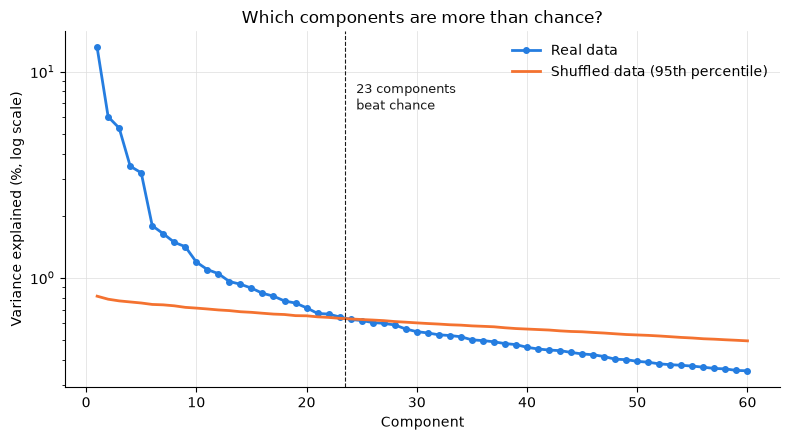

In [7]:
shuffled = clustering.shuffled_variance(z, config.N_SHUFFLES, config.MAX_COMPONENTS)   # 20 shuffles
threshold = clustering.noise_threshold(shuffled, config.NOISE_PERCENTILE)               # chance level per component
n_real = clustering.count_real_components(real_variance, threshold)

print("Components that beat chance:", n_real)
print("Variance they explain (%):", round(real_variance[:n_real].sum() * 100, 1))
fig = clustering.plot_scree(real_variance, threshold, n_real)   # blue = real, orange = shuffled

The real components (blue) start far above chance (orange) and cross it after about two dozen. Those explain about half of the variance. The other half is **company-specific movement** (earnings, news) that no other stock shares, so it cannot help to group stocks.

We keep only the real components.

In [8]:
pca, scores = clustering.fit_pca(z, n_components=n_real)   # keep only the real components
print("Scores used for clustering:", scores.shape, "(stocks x components)")

Scores used for clustering: (495, 23) (stocks x components)


## 5. What do the first two components mean?

A component is read by looking at which stocks score high and which score low. Here: the average score per sector. The sign is arbitrary, only opposite ends matter.

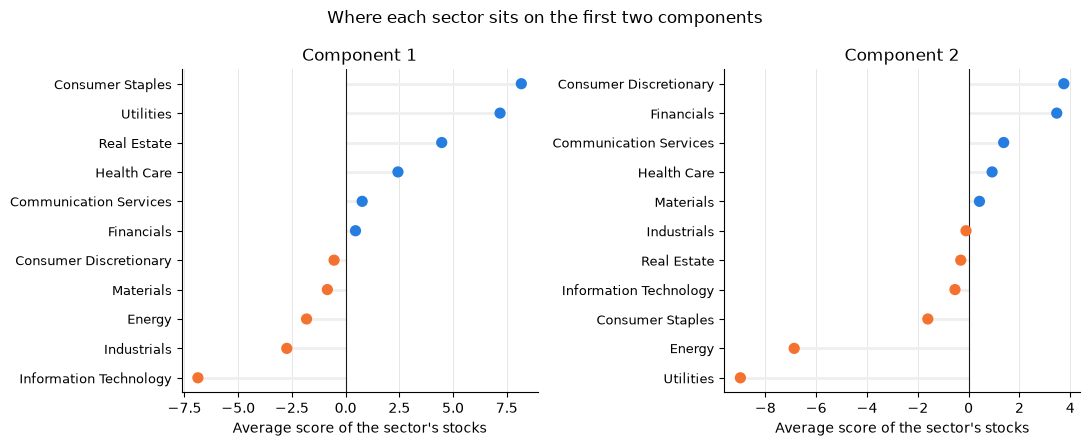

In [9]:
sector_scores = clustering.sector_mean_scores(scores, labels)   # average score per sector
fig = clustering.plot_sector_scores(sector_scores)

- **Component 1 = growth vs defensive.** Information Technology at one end; Consumer Staples, Utilities and Real Estate at the other. With the market removed, the biggest pattern is money rotating between the two.
- **Component 2:** Utilities and Energy (interest rates, commodity prices) vs Consumer Discretionary and Financials (economic cycle).

Neither matches a single sector. KMeans uses all the real components together.

## 6. KMeans and the silhouette score

**KMeans** splits the stocks into $k$ groups: place $k$ centres, assign every stock to the nearest centre, move each centre to the middle of its stocks, repeat. It runs 10 times from different starts with a fixed seed, and keeps the best result.

To choose $k$ we use the **silhouette score**. Per stock: is it closer to its own group than to the nearest other group? Near 1 = clearly in the right group, 0 = on the border, negative = closer to another group. The score works for any grouping, so we can also score the **official sectors** the same way.

Silhouette of the official sectors: 0.076


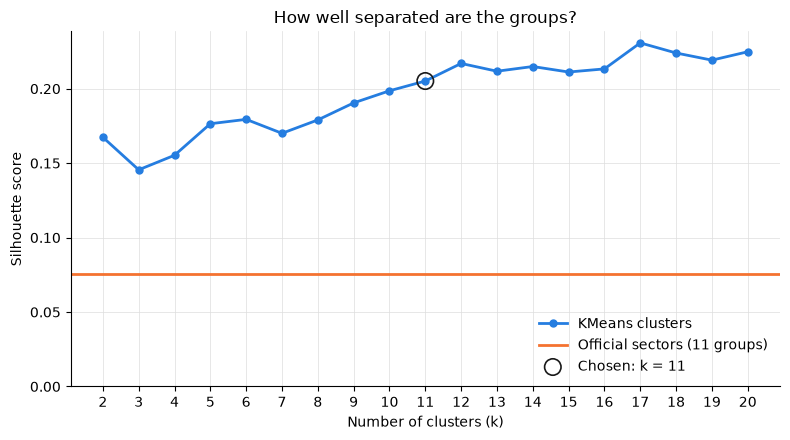

In [10]:
sweep = clustering.silhouette_sweep(scores, range(2, 21))                   # KMeans for k = 2 ... 20
sector_silhouette = silhouette_score(scores, labels["sector"].to_numpy())   # sectors as the groups
print("Silhouette of the official sectors:", round(sector_silhouette, 3))
fig = clustering.plot_silhouette_sweep(sweep, sector_silhouette, config.N_CLUSTERS)

- **No clear best k:** the score rises slowly and flattens. All scores are low, so stocks form a continuum rather than tight separate groups.
- **We choose k = 11**, the same number as sectors, for a like-for-like comparison. It sits close to the flat part.
- **Every k beats the official sectors.** The data finds groups that separate stocks much better than the labels do.

In [11]:
cluster = clustering.fit_kmeans(scores, config.N_CLUSTERS)   # final clustering: a cluster number per stock
print("Silhouette, KMeans clusters:", round(silhouette_score(scores, cluster), 3))
print("Silhouette, official sectors:", round(sector_silhouette, 3))

Silhouette, KMeans clusters: 0.205
Silhouette, official sectors: 0.076


The comparison above is **one number per grouping**: KMeans clusters vs official sectors, same space, same number of groups.

## 7. Which sectors hold together?

This table uses the **official sectors as the groups, not the KMeans clusters**. It splits the sectors' silhouette score into one value per sector:

- **positive**: the sector's stocks are closer to each other than to the nearest other sector
- **around 0**: on the border between their own sector and another one
- **negative**: on average closer to another sector than to their own

In [12]:
clustering.silhouette_per_sector(scores, labels)

sector,silhouette,n_stocks
str,f64,u32
"""Energy""",0.42838,21
"""Utilities""",0.301469,31
"""Consumer Staples""",0.187187,32
"""Real Estate""",0.136322,30
"""Consumer Discretionary""",0.069789,47
"""Financials""",0.049972,76
"""Information Technology""",0.048554,74
"""Communication Services""",0.048007,19
"""Health Care""",0.033431,60


This agrees with the correlation analysis in notebook 02 (within vs cross-sector correlation), found with a different method: **Energy and Utilities** are clear groups; **Industrials and Materials** are, on average, closer to other sectors than to their own. Which clusters these stocks actually end up in is the next step (cluster x sector crosstab).

In [13]:
result = clustering.save_clusters(labels, cluster, scores)   # saved for the next notebook
print("Saved:", config.CLUSTERS_PATH.name, result.shape)

Saved:

 clusters.parquet (495, 26)


## Summary

- Standardising each stock makes clusters group stocks that move **together**, not stocks that are equally volatile.
- scikit-learn's PCA removes the market move; the first component is then **growth vs defensive**.
- A shuffle test keeps about two dozen real components (about half the variance); the rest is company-specific noise.
- KMeans with 11 clusters separates stocks much better than the 11 official sectors.
- **Energy and Utilities** are coherent sectors; **Industrials and Materials** are not.

**Next:** cross-tabulate clusters against sectors and find stocks that sit outside their sector's cluster.